<a href="https://colab.research.google.com/github/abdulkholik-Jdev/slp-iris-classification/blob/main/SLP_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Single Layer Perceptron (SLP) - Klasifikasi Biner Iris
Setosa = 0, Versicolor = 1. Replikasi spreadsheet SLP (Assignment 1).

**Sebelum menjalankan:** unggah `iris_binary.csv` ke folder Colab (ikon folder di kiri), lalu pilih *Runtime > Run all*.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import dan konfigurasi

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LEARNING_RATE = 0.1
EPOCHS = 5
INIT_WEIGHT = 0.5          # bias dan teta1..teta4 awal = 0.5
N_TRAIN_PER_CLASS = 40     # 40 latih + 10 validasi per kelas
DATA_FILE = "/content/drive/MyDrive/KECERDASAN BUATAN LANJUT/iris_binary.csv"

## 2. Load data dan split
40 data pertama tiap kelas untuk latih (80), 10 sisanya untuk validasi (20). Urutan dipertahankan seperti di spreadsheet (tanpa shuffle).

In [8]:
df = pd.read_csv(DATA_FILE)
df["target"] = df["species"].map({"Iris-setosa": 0, "Iris-versicolor": 1})
X = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]].values
y = df["target"].values.astype(float)

tr_idx, va_idx = [], []
for c in (0, 1):
    idx = np.where(y == c)[0]
    tr_idx += list(idx[:N_TRAIN_PER_CLASS])
    va_idx += list(idx[N_TRAIN_PER_CLASS:])
X_train, y_train = X[tr_idx], y[tr_idx]
X_val, y_val = X[va_idx], y[va_idx]
print("Data latih :", X_train.shape, "| Data validasi:", X_val.shape)

Data latih : (80, 4) | Data validasi: (20, 4)


## 3. Model SLP
- z = bias + teta1*X1 + ... + teta4*X4
- g(z) = 1 / (1 + exp(-z))  (sigmoid)
- Loss per sampel = (g - target)^2
- Gradien: dE/dw = 2 (g - t) (1 - g) g x   (bias: x = 1)
- Update per sampel: w = w - learning_rate * gradien

In [9]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def train_epoch(X, y, w, lr=LEARNING_RATE):
    """Satu epoch (update bobot tiap sampel). w = [bias, teta1..teta4]."""
    w = w.copy()
    g_all = np.zeros(len(X))
    for i, (x, t) in enumerate(zip(X, y)):
        xb = np.concatenate(([1.0], x))
        g = sigmoid(w @ xb)                        # prediksi dgn bobot sebelum update
        g_all[i] = g
        grad = 2.0 * (g - t) * (1.0 - g) * g * xb  # dbias, dteta1..dteta4
        w = w - lr * grad
    return w, g_all

def evaluate(X, y, w):
    """Validasi: bobot tetap (hasil akhir training epoch tsb), tanpa update."""
    Xb = np.hstack([np.ones((len(X), 1)), X])
    return sigmoid(Xb @ w)

def loss_acc(g, y):
    pred = (g > 0.5).astype(int)
    return np.mean((g - y) ** 2), np.mean(pred == y)

## 4. Training dan validasi per epoch

In [10]:
w = np.full(5, INIT_WEIGHT)
rows = []
for ep in range(1, EPOCHS + 1):
    w, g_tr = train_epoch(X_train, y_train, w)
    g_va = evaluate(X_val, y_val, w)
    l_tr, a_tr = loss_acc(g_tr, y_train)
    l_va, a_va = loss_acc(g_va, y_val)
    rows.append([ep, a_tr, a_va, l_tr, l_va])

hist = pd.DataFrame(rows, columns=["Epoch", "Acc Training", "Acc Validation", "Loss Training", "Loss Validation"])
display(hist.round(6))
print("Bobot akhir [bias, teta1..teta4]:", np.round(w, 6))

,Epoch,Acc Training,Acc Validation,Loss Training,Loss Validation
0,1,0.5250,0.50,0.449889,0.328951
1,2,0.9500,0.50,0.037452,0.247289
2,3,0.9750,0.50,0.024372,0.175892
3,4,0.9750,0.85,0.017357,0.119381
4,5,0.9875,1.00,0.012740,0.081581


Bobot akhir [bias, teta1..teta4]: [ 0.25772  -0.241802 -0.416903  1.122214  0.824059]


## 5. Chart akurasi dan loss

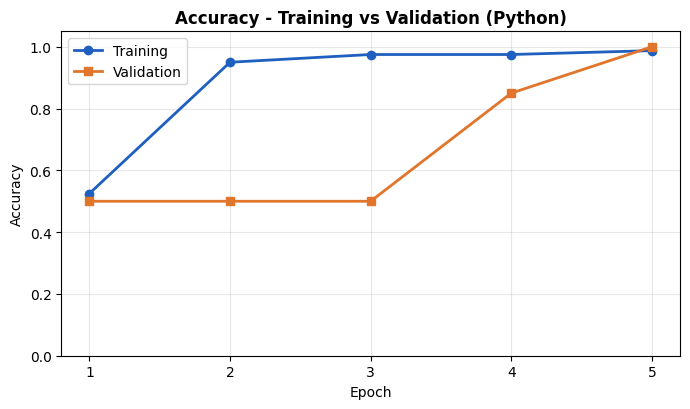

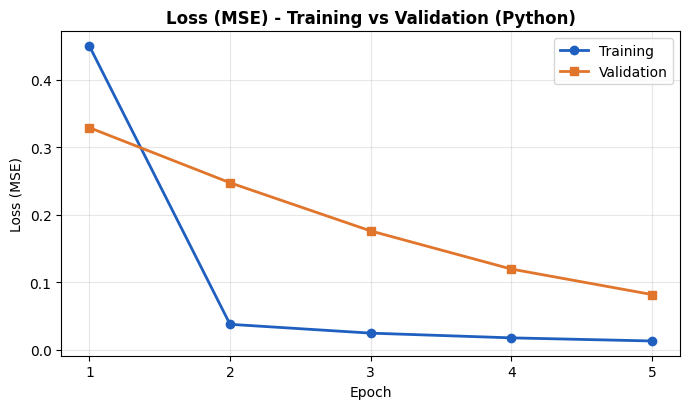

In [11]:
def plot(cols, title, ylabel, fname, ylim=None):
    plt.figure(figsize=(7, 4.2))
    plt.plot(hist["Epoch"], hist[cols[0]], "o-", color="#1f5fbf", lw=2, label="Training")
    plt.plot(hist["Epoch"], hist[cols[1]], "s-", color="#e0752b", lw=2, label="Validation")
    plt.title(title, fontweight="bold"); plt.xlabel("Epoch"); plt.ylabel(ylabel)
    plt.xticks(hist["Epoch"]); plt.grid(alpha=0.3); plt.legend()
    if ylim: plt.ylim(*ylim)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

plot(["Acc Training", "Acc Validation"], "Accuracy - Training vs Validation (Python)", "Accuracy", "accuracy_chart.png", (0, 1.05))
plot(["Loss Training", "Loss Validation"], "Loss (MSE) - Training vs Validation (Python)", "Loss (MSE)", "loss_chart.png")